<div dir="rtl">

# الحلقة 3: Exploration vs Exploitation، والـ MDP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mmmohamedaaashraf/deep-rl-arabic/blob/main/ep03-exploration/ep03_exploration.ipynb)

**سلسلة Deep RL بالعربي**، مبنية على [كورس Hugging Face Deep RL](https://huggingface.co/learn/deep-rl-course) (Unit 1: Exploration/Exploitation tradeoff + The two main approaches)،
ومدعومة بالفصل التاني (Multi-armed Bandits) والفصل التالت (MDP) من كتاب Sutton & Barto: *Reinforcement Learning: An Introduction* (2nd ed.).

### إحنا فين؟
- **الحلقة 1:** الـ RL loop، والـ agent العشوائي على LunarLander.
- **الحلقة 2:** هدف الـ agent هو الـ return، والـ γ بيحدد بيشوف لقدام قد إيه. والـ PPO دفع بنزين دلوقتي عشان يهبط بعدين.
- **النهارده:** الـ agent لسه مايعرفش أنهي action أحسن. يجرّب حاجة جديدة (exploration) ولا يكرر اللي شافها كويسة (exploitation)؟ وبعدين: الـ MDP، والـ state vs observation، ونوعين الـ actions، والطريقتين الأساسيتين لحل الـ RL.
- **الحلقة الجاية:** أول مشروع كامل: ندرب PPO على LunarLander من الصفر.

**على Colab:** `Runtime > Run all`. النوتبوك كله بيشتغل على CPU في دقايق.
</div>

<div dir="rtl">

## 0) التجهيز
</div>

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "swig"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[box2d]==1.4.0", "stable-baselines3==2.9.2"], check=True)

import os, urllib.request
import numpy as np, matplotlib.pyplot as plt, gymnasium as gym
import stable_baselines3
from stable_baselines3 import PPO
print("gymnasium", gym.__version__, "| stable-baselines3", stable_baselines3.__version__)

gymnasium 1.4.0 | stable-baselines3 2.9.2


<div dir="rtl">

## 1) المشكلة: الـ agent مايعرفش الـ reward قبل ما يجرّب
تخيل 10 زراير، كل زرار بيدي reward عشوائي حوالين متوسط مختلف، وإنت **ماتعرفش** المتوسطات.
عندك 1000 محاولة. كل مرة تدوس على زرار واحد (action) وتاخد reward.
- لو فضلت تدوس على الزرار اللي **شايفه أحسن لحد دلوقتي** → **exploitation** (استغلال).
- لو جربت زرار تاني يمكن يطلع أحسن → **exploration** (استكشاف).

دي اسمها **10-armed bandit** (في الكتاب كل اختيار اسمه arm، وإحنا هنسميه زرار) (الفصل 2 في Sutton & Barto). مافيهاش states: action → reward وخلاص. أبسط شكل للـ RL.
</div>

button 0: true mean = +0.13
button 1: true mean = -0.13
button 2: true mean = +0.64
button 3: true mean = +0.10
button 4: true mean = -0.54
button 5: true mean = +0.36
button 6: true mean = +1.30   <- best
button 7: true mean = +0.95
button 8: true mean = -0.70
button 9: true mean = -1.27


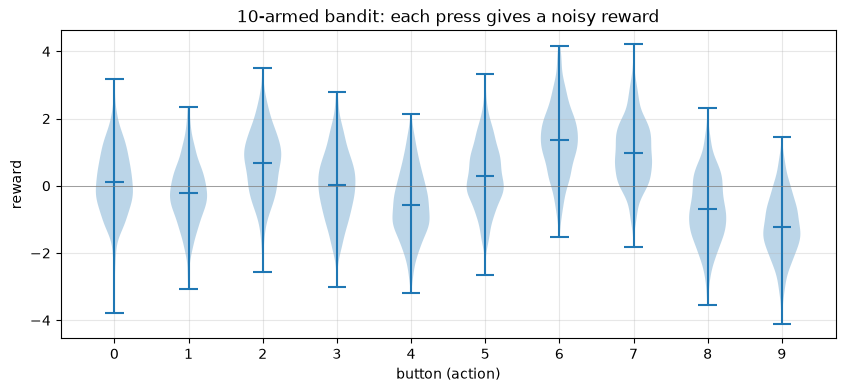

In [2]:
K = 10
rng = np.random.default_rng(0)
q_true = rng.normal(0, 1, K)          # the true mean reward of each button (hidden from the agent)
best = int(np.argmax(q_true))
for a, q in enumerate(q_true):
    print(f"button {a}: true mean = {q:+.2f}" + ("   <- best" if a == best else ""))

samples = [q_true[a] + rng.normal(0, 1, 500) for a in range(K)]
plt.figure(figsize=(10, 4))
plt.violinplot(samples, positions=range(K), showmeans=True)
plt.axhline(0, color="gray", lw=.5)
plt.xlabel("button (action)"); plt.ylabel("reward"); plt.title("10-armed bandit: each press gives a noisy reward")
plt.xticks(range(K)); plt.grid(alpha=.3); plt.show()

<div dir="rtl">

## 2) الـ agent بيقدّر قيمة كل action: Q(a)
الـ agent مايعرفش `q_true`. فبيحسب **تقدير** لكل action = متوسط الـ rewards اللي خدها منها لحد دلوقتي:

$$Q(a) = \frac{\text{مجموع الـ rewards من } a}{\text{عدد مرات اختيار } a}$$

ونفس المتوسط ممكن يتحسب خطوة بخطوة من غير ما نخزن كل الـ rewards (incremental update):

$$Q \leftarrow Q + \frac{1}{N}\,(R - Q)$$

يعني: التقدير الجديد = القديم + خطوة صغيرة ناحية الغلطة (R - Q). الشكل ده هيرجعلنا كتير (Q-Learning في الوحدة 2).
</div>

In [3]:
def run_bandit(q_true, epsilon, steps=1000, seed=0):
    """epsilon-greedy agent on one bandit. Returns rewards, chosen actions, final Q estimates."""
    rng = np.random.default_rng(seed)
    K = len(q_true)
    Q = np.zeros(K)           # estimates, start at 0
    N = np.zeros(K)           # how many times each button was pressed
    rewards, actions = np.zeros(steps), np.zeros(steps, dtype=int)
    for t in range(steps):
        if rng.random() < epsilon:
            a = int(rng.integers(K))                                 # explore: random button
        else:
            a = int(rng.choice(np.flatnonzero(Q == Q.max())))         # exploit: best estimate (ties broken randomly)
        r = q_true[a] + rng.normal()                                  # the environment answers
        N[a] += 1
        Q[a] += (r - Q[a]) / N[a]                                     # incremental average
        rewards[t], actions[t] = r, a
    return rewards, actions, Q

single = {}
for eps in [0.0, 0.1]:
    r, a, Q = run_bandit(q_true, eps, seed=2)
    stuck = int(np.bincount(a, minlength=K).argmax())
    single[eps] = (float(np.mean(a == best) * 100), stuck, float(r.mean()))
    print(f"epsilon={eps}: picked the best button {np.mean(a == best) * 100:5.1f}% of the time | "
          f"most pressed button = {stuck} (true mean {q_true[stuck]:+.2f}) | mean reward = {r.mean():+.2f}")
    print("   its Q estimates:", np.round(Q, 2))

epsilon=0.0: picked the best button   0.0% of the time | most pressed button = 3 (true mean +0.10) | mean reward = +0.02
   its Q estimates: [ 0.   -0.55  0.    0.02  0.    0.    0.    0.    0.    0.  ]
epsilon=0.1: picked the best button  81.1% of the time | most pressed button = 6 (true mean +1.30) | mean reward = +1.10
   its Q estimates: [-0.26 -0.6   0.64 -0.23 -0.28  0.19  1.3   0.41 -0.98 -1.5 ]


<div dir="rtl">

**الـ greedy (ε = 0)** بيدوس على أول زرار اداله reward كويس، ويفضل عليه للأبد، لأنه عمره ما بيجرب غيره.
**الـ ε-greedy** معظم الوقت بيستغل، بس بنسبة ε بيجرب action عشوائية. ده اللي بيخليه يلاقي الأحسن.

بس دي تجربة واحدة. ممكن تكون حظ. نعيدها على **2000 bandit مختلفين** زي الكتاب بالظبط.
</div>

<div dir="rtl">

## 3) التجربة الكبيرة: 2000 bandit × 1000 خطوة
</div>

In [4]:
RUNS, STEPS = 2000, 1000
EPSILONS = [0.0, 0.01, 0.1]

def experiment(epsilon, runs=RUNS, steps=STEPS, init=0.0):
    """Vectorized: all runs at once. Returns mean reward per step and % optimal action per step."""
    rng = np.random.default_rng(123)                     # same 2000 bandits for every epsilon
    q = rng.normal(0, 1, (runs, K))
    opt = q.argmax(1)
    rng_play = np.random.default_rng(7)
    Q, N = np.full((runs, K), init, dtype=float), np.zeros((runs, K))
    avg_r, pct_opt = np.zeros(steps), np.zeros(steps)
    idx = np.arange(runs)
    for t in range(steps):
        noise = rng_play.random((runs, K)) * 1e-9         # random tie-break
        greedy = (Q + noise).argmax(1)
        explore = rng_play.random(runs) < epsilon
        a = np.where(explore, rng_play.integers(0, K, runs), greedy)
        r = q[idx, a] + rng_play.normal(size=runs)
        N[idx, a] += 1
        Q[idx, a] += (r - Q[idx, a]) / N[idx, a]
        avg_r[t], pct_opt[t] = r.mean(), (a == opt).mean() * 100
    return avg_r, pct_opt

results = {eps: experiment(eps) for eps in EPSILONS}
for eps, (avg_r, pct) in results.items():
    print(f"epsilon={eps:<5} avg reward (last 100 steps) = {avg_r[-100:].mean():.2f} | "
          f"best button chosen at step 1000 = {pct[-1]:5.1f}% | over the last 100 steps = {pct[-100:].mean():5.1f}%")

epsilon=0.0   avg reward (last 100 steps) = 1.04 | best button chosen at step 1000 =  35.1% | over the last 100 steps =  35.1%
epsilon=0.01  avg reward (last 100 steps) = 1.32 | best button chosen at step 1000 =  61.0% | over the last 100 steps =  60.3%
epsilon=0.1   avg reward (last 100 steps) = 1.38 | best button chosen at step 1000 =  82.2% | over the last 100 steps =  80.7%


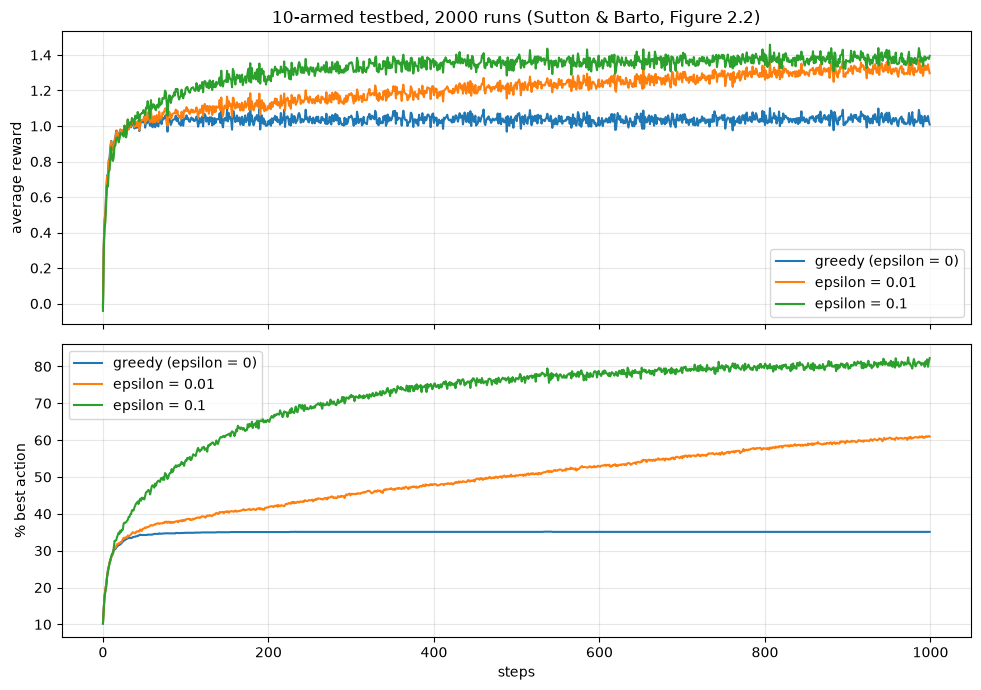

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
names = {0.0: "greedy (epsilon = 0)", 0.01: "epsilon = 0.01", 0.1: "epsilon = 0.1"}
for eps, (avg_r, pct) in results.items():
    ax[0].plot(avg_r, label=names[eps]); ax[1].plot(pct, label=names[eps])
ax[0].set_ylabel("average reward"); ax[1].set_ylabel("% best action"); ax[1].set_xlabel("steps")
ax[0].legend(); ax[1].legend(); ax[0].grid(alpha=.3); ax[1].grid(alpha=.3)
ax[0].set_title("10-armed testbed, 2000 runs (Sutton & Barto, Figure 2.2)")
plt.tight_layout(); plt.show()

<div dir="rtl">

**نقرا الرسمة:**
- الـ **greedy** بيطلع بسرعة في الأول، وبعدين **بيقف**: بيختار الأحسن في 35% بس من الحالات، يعني في حوالي تلتين الحالات لزق في زرار مش الأحسن.
- **ε = 0.1** بيستكشف كتير، فبيلاقي الأحسن بدري، بس عمره ما هيختاره أكتر من حوالي 91% (لأنه 10% من الوقت بيختار عشوائي).
- **ε = 0.01** بطيء في الأول، بس على المدى الطويل هيعدّي الـ 0.1.

ده الـ **tradeoff**: كل exploration بتكلفك reward دلوقتي، بس من غيرها ممكن ماتعرفش أبدًا إن فيه حاجة أحسن.
نفس فكرة الحلقة 2: تدفع دلوقتي عشان تكسب بعدين.
</div>

<div dir="rtl">

## 4) طب الـ PPO بتاعنا بيستكشف إزاي؟
الـ PPO مافيهوش ε. الـ policy بتاعته بتطلع **احتمالات**، وأثناء التدريب بيختار الـ action **بالقرعة** من الاحتمالات دي (stochastic).
يعني الـ exploration جوه الـ policy نفسها: لو مش متأكد، الاحتمالات بتبقى قريبة من بعض فبيجرب. ولو متأكد، احتمال واحد بيكبر.

بعد التدريب بنقدر نشغله **deterministic**: ياخد الـ action اللي احتمالها أعلى دايمًا (exploitation بس). نقارن الاتنين على نفس الـ 100 seed:
</div>

In [6]:
MODEL = "ppo-LunarLander-v3.zip"
if not os.path.exists(MODEL):
    urllib.request.urlretrieve("https://github.com/mmmohamedaaashraf/deep-rl-arabic/raw/main/ep01-what-is-rl/" + MODEL, MODEL)
model = PPO.load(MODEL, device="cpu")

def evaluate(deterministic, seeds=range(100)):
    totals, landed, legs_down, lengths = [], 0, 0, []
    env = gym.make("LunarLander-v3")
    for seed in seeds:
        obs, _ = env.reset(seed=seed)
        done, total, last, n = False, 0.0, 0.0, 0
        while not done:
            a, _ = model.predict(obs, deterministic=deterministic)
            obs, r, term, trunc, _ = env.step(int(a))
            total += r; last = r; n += 1; done = term or trunc
        totals.append(total); lengths.append(n)
        landed += last == 100                 # landed AND came to rest -> +100
        legs_down += obs[6] + obs[7] == 2     # both legs on the ground at the end
    env.close()
    return np.mean(totals), np.std(totals), landed, legs_down, np.mean(lengths)

import torch
torch.manual_seed(0)
ppo_eval = {}
for det in [True, False]:
    m, s, l, legs, n = evaluate(det)
    ppo_eval["deterministic" if det else "stochastic"] = (m, s, l, legs, n)
    print(f"{'deterministic (exploit only)' if det else 'stochastic (sample from probs)':31s} mean = {m:+6.1f}  std = {s:4.1f} | "
          f"both legs down = {legs:3d}/100 | landed and stopped (+100) = {l:3d}/100 | avg steps = {n:6.1f}")

deterministic (exploit only)    mean = +238.4  std = 22.6 | both legs down =  97/100 | landed and stopped (+100) = 100/100 | avg steps =  447.1


stochastic (sample from probs)  mean = +146.5  std = 33.4 | both legs down =  97/100 | landed and stopped (+100) =   3/100 | avg steps =  973.6


<div dir="rtl">

**نتيجة مهمة:** الـ stochastic بيوصل الأرض على رجليه تقريبًا كل مرة، بس بيفضل **يشغّل الموتور بالقرعة** كل شوية، فالمركبة عمرها ما بتقف.
فمابياخدش الـ **+100** بتاعة الهبوط، والحلقة بتتقطع عند **1000 خطوة** وهو بيصرف بنزين.

ده **تمن الـ exploration**: مفيد جدًا **أثناء** التدريب عشان الـ agent يكتشف، لكن **بعد** التدريب عايزين exploitation بس.
عشان كده بنقيّم الموديلات دايمًا بـ `deterministic=True`، وده اللي هنعمله في الحلقة الجاية لما ندرب PPO من الصفر.
</div>

<div dir="rtl">

## 5) من الـ bandit للـ MDP: لما يبقى فيه state
في الـ bandit، أحسن action واحدة دايمًا. في LunarLander، أحسن action **بتعتمد على الموقف**: المركبة بتقع بسرعة؟ شغّل الموتور. مايلة شمال؟ صحّحها.

ده الـ **MDP (Markov Decision Process)**: الإطار الرياضي لأي مشكلة RL، وبيتكون من:
- **S**: الـ states
- **A**: الـ actions
- **P(s' | s, a)**: الـ environment بيودّيك فين لو عملت a في s
- **R**: الـ reward
- **γ**: الـ discount (من الحلقة 2)

**الـ Markov property:** الـ state الحالية فيها **كل** اللي محتاجه عشان تقرر. مش محتاج تفتكر اللي فات.
</div>

In [7]:
LABELS = ["x", "y", "vx", "vy", "angle", "angular vel", "left leg", "right leg"]
env = gym.make("LunarLander-v3")
obs, _ = env.reset(seed=44)
for name, v in zip(LABELS, obs):
    print(f"{name:12s} = {v:+.3f}")
print("observation_space:", env.observation_space)
env.close()

x            = +0.007
y            = +1.421
vx           = +0.711
vy           = +0.432
angle        = -0.008
angular vel  = -0.161
left leg     = +0.000
right leg    = +0.000
observation_space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)


<div dir="rtl">

### ليه السرعة لازم تبقى جوه الـ state؟
نسأل الـ PPO المتدرب: نفس **المكان** بالظبط (seed 44)، ونغيّر **السرعة الرأسية** `vy` بس. هيختار نفس الـ action؟
</div>

In [8]:
def ppo_probs(obs):
    obs_t, _ = model.policy.obs_to_tensor(obs)
    with torch.no_grad():
        return model.policy.get_distribution(obs_t).distribution.probs[0].cpu().numpy()

ACTIONS = ["do nothing", "left engine", "main engine", "right engine"]
env = gym.make("LunarLander-v3")
obs44, _ = env.reset(seed=44); env.close()
markov = {}
for vy in [0.0, -0.5, -1.0]:
    o = obs44.copy(); o[3] = vy            # same x, y, angle ... only the vertical speed changes
    p = ppo_probs(o)
    markov[vy] = p
    print(f"vy = {vy:+.1f} -> " + " | ".join(f"{n} {100 * q:5.1f}%" for n, q in zip(ACTIONS, p)) + f"   => {ACTIONS[p.argmax()]}")

vy = +0.0 -> do nothing   3.5% | left engine  96.3% | main engine   0.1% | right engine   0.0%   => left engine
vy = -0.5 -> do nothing   0.1% | left engine  21.4% | main engine  78.5% | right engine   0.0%   => main engine
vy = -1.0 -> do nothing   0.0% | left engine   0.3% | main engine  99.7% | right engine   0.0%   => main engine


<div dir="rtl">

نفس المكان، لكن لما المركبة **ثابتة** الـ PPO بيعدّل الاتجاه بالموتور الجانبي، ولما **بتقع بسرعة** بيشغّل الموتور الرئيسي بنسبة شبه 100%.
لو الـ state فيها المكان بس، الحالتين هيبانوا **نفس الحاجة**، ومستحيل يختار صح. عشان كده Gymnasium بيحط السرعة والسرعة الزاوية جوه الـ 8 أرقام: من غيرهم الـ state **مش Markov**.
</div>

<div dir="rtl">

## 6) State ولا Observation؟
- **State:** وصف **كامل** للدنيا (fully observed). الـ 8 أرقام في LunarLander قريبة من كده.
- **Observation:** وصف **جزئي** (partially observed). زي صورة من الشاشة: صورة واحدة مافيهاش السرعة.

نفس اللعبة ممكن تديك الاتنين:
</div>

vector state : (8,) -> 8 numbers
image frame  : (400, 600, 3) -> 720000 numbers


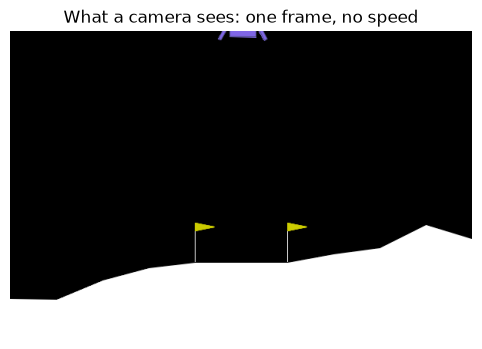

In [9]:
env = gym.make("LunarLander-v3", render_mode="rgb_array")
obs, _ = env.reset(seed=44)
frame = env.render()
env.close()
print("vector state :", obs.shape, "->", obs.size, "numbers")
print("image frame  :", frame.shape, "->", frame.size, "numbers")
plt.figure(figsize=(6, 4)); plt.imshow(frame); plt.axis("off"); plt.title("What a camera sees: one frame, no speed"); plt.show()

<div dir="rtl">

الصورة فيها **720,000** رقم ومع ذلك **ناقصها** السرعة. عشان كده في ألعاب Atari (الوحدة 3) بنحط **4 صور ورا بعض** (frame stacking) عشان الـ agent يقدر يستنتج الحركة.
</div>

<div dir="rtl">

## 7) الـ Action space: Discrete ولا Continuous؟
- **Discrete:** عدد محدود من الاختيارات. LunarLander: 4 actions (ولا حاجة، شمال، الرئيسي، يمين).
- **Continuous:** أرقام حقيقية. نسخة LunarLander الـ continuous: رقمين، قوة الموتور الرئيسي وقوة الجانبي، كل واحد من 1- لـ 1.

نوع الـ action space بيحدد أنهي algorithm ينفع: DQN مثلًا للـ discrete بس، و SAC للـ continuous (هنشوفهم في الوحدات الجاية).
</div>

In [10]:
d = gym.make("LunarLander-v3")
c = gym.make("LunarLander-v3", continuous=True)
print("discrete  :", d.action_space, "   example:", d.action_space.sample())
print("continuous:", c.action_space, "   example:", np.round(c.action_space.sample(), 3))
d.close(); c.close()

discrete  : Discrete(4)    example: 3
continuous: Box(-1.0, 1.0, (2,), float32)    example: [-0.189  0.69 ]


<div dir="rtl">

## 8) الطريقتين الأساسيتين لحل الـ RL
هدفنا policy **π**: المخ اللي بياخد state ويطلع action. فيه طريقتين نوصله:

1. **Value-based:** نتعلم **قيمة** كل action (زي Q في الـ bandit)، والـ policy بتبقى قاعدة ثابتة: "اختار الأعلى قيمة". ده اللي عملناه في أول النوتبوك. (Q-Learning و DQN في الوحدتين 2 و 3.)
2. **Policy-based:** نتعلم الـ policy **مباشرة**: network تطلع احتمال لكل action. ده الـ PPO بتاعنا. (الوحدات 4 و 5.)

نحط الاتنين جنب بعض من حاجات إحنا شغلناها النهارده:
</div>

VALUE-BASED (bandit, epsilon = 0.1): learned Q per button
   [-0.26 -0.6   0.64 -0.23 -0.28  0.19  1.3   0.41 -0.98 -1.5 ] -> action = argmax = 6
POLICY-BASED (PPO, seed 44 first state): probability per action
   [24.5 75.4  0.   0.1] % -> action sampled from these


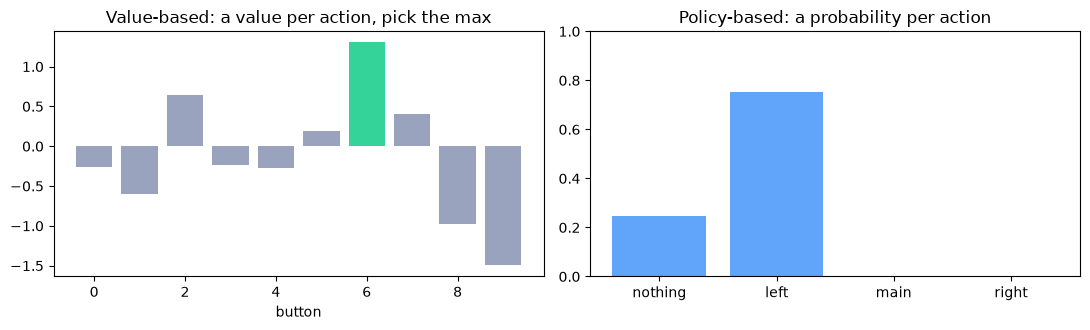

In [11]:
_, _, Q_learned = run_bandit(q_true, 0.1, steps=1000, seed=2)   # the epsilon = 0.1 agent from section 2
probs = ppo_probs(obs44)

print("VALUE-BASED (bandit, epsilon = 0.1): learned Q per button")
print("  ", np.round(Q_learned, 2), "-> action = argmax =", int(Q_learned.argmax()))
print("POLICY-BASED (PPO, seed 44 first state): probability per action")
print("  ", np.round(probs * 100, 1), "% -> action sampled from these")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(range(K), Q_learned, color=["#34D399" if i == Q_learned.argmax() else "#9AA3BD" for i in range(K)])
ax[0].set_title("Value-based: a value per action, pick the max"); ax[0].set_xlabel("button")
ax[1].bar(["nothing", "left", "main", "right"], probs, color="#60A5FA")
ax[1].set_title("Policy-based: a probability per action"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

<div dir="rtl">

## الخلاصة
1. الـ agent مايعرفش قيمة الـ actions غير لما يجربها: لازم يوازن بين **exploration** و **exploitation**.
2. **ε-greedy:** استغل معظم الوقت، وجرّب عشوائي بنسبة ε. الـ greedy البحت بيلزق في اختيار مش الأحسن.
3. **Q ← Q + (1/N)(R − Q):** تحديث التقدير خطوة بخطوة ناحية الغلطة.
4. الـ PPO بيستكشف من خلال الاحتمالات (stochastic policy) مش ε.
5. **MDP** = (S, A, P, R, γ). والـ **Markov property**: الـ state فيها كل اللي محتاجه، وعشان كده السرعة جوه الـ state.
6. **State** كاملة، **observation** جزئية (صورة واحدة مافيهاش سرعة).
7. **Discrete** vs **continuous** actions بيحدد الـ algorithm.
8. **Value-based** (نتعلم قيم ونختار الأعلى) vs **policy-based** (نتعلم الاحتمالات مباشرة).

**جرّب بنفسك:**
- جرّب ε = 0.05 في التجربة الكبيرة. فين بيقع بين 0.01 و 0.1؟
  *تلميح: غيّر `EPSILONS` وشغّل الخليتين تاني.*
- **Optimistic initial values** (Sutton & Barto 2.6): خلي التقدير المبدئي Q = 5 بدل 0 مع greedy (ε = 0). إيه اللي بيحصل؟
  *تلميح: `experiment(0.0, init=5.0)`. كل زرار هيخيّب أمله في الأول، فهيجرّبهم كلهم لوحده.*
- في خلية الـ Markov جرّب `o[4]` (الزاوية) بدل `vy`: ميّل المركبة 0.3 يمين و 0.3 شمال، والـ PPO بيختار إيه؟
  *تلميح: `o[4] = 0.3` ثم `o[4] = -0.3`.*

**المراجع:**
- Hugging Face Deep RL Course, Unit 1: The Exploration/Exploitation tradeoff, Two main approaches for solving RL problems
- Sutton & Barto, *Reinforcement Learning: An Introduction* (2nd ed.), Chapter 2.1 – 2.4, 2.6 and Chapter 3.1
- OpenAI Spinning Up, Part 1: Key Concepts in RL (states and observations, action spaces, policies)
- Gymnasium docs: LunarLander

عندك سؤال؟ اكتبه في كومنت على الفيديو:
[LinkedIn](https://www.linkedin.com/in/mohamed-ashraf0) · [Facebook](https://www.facebook.com/MohamedAshrafIN) · [YouTube](https://www.youtube.com/@MmmohamedAaashraf)
</div>